In [3]:
from data_import import load_data, create_train_val_sets
from feature_selection import add_features, drop_features
from model_training import train_and_val_model, ams
from sklearn.ensemble import RandomForestClassifier
import numpy as np
import pandas as pd
import xgboost as xgb

df_train, df_test = load_data()

In [5]:
def create_extended_df(df):
    df = add_features(df)
    df.replace(-999.0, np.nan, inplace = True)
    df.info()
    return df

def create_simplified_df(df):
    df = drop_features(df)
    df.replace(-999.0, np.nan, inplace = True)
    df.info()
    return df

def drop_nans(df):
    df.replace(-999.0, np.nan, inplace = True)
    df.info()
    return df


In [44]:
xgb_model = xgb.XGBClassifier(n_jobs = -1, 
                             tree_method = "hist",
                            )

xgb_param_grid = {"n_estimators": [50, 100, 200],
                  "max_depth": [8, 10, 12],
                  "learning_rate": [0.005, 0.01, 0.05],
                }

df_extended = create_extended_df(df_train)
df_simplified = create_simplified_df(df_train)
df_train_nans = drop_nans(df_train)

df_description = ["Starting training with extended features:",
                    "Starting training with simplified features:",
                    "Starting training with original features:"]


<class 'pandas.DataFrame'>
RangeIndex: 654590 entries, 0 to 654589
Data columns (total 36 columns):
 #   Column                       Non-Null Count   Dtype  
---  ------                       --------------   -----  
 0   DER_mass_MMC                 554905 non-null  float64
 1   DER_mass_transverse_met_lep  654590 non-null  float64
 2   DER_mass_vis                 654590 non-null  float64
 3   DER_pt_h                     654590 non-null  float64
 4   DER_deltaeta_jet_jet         190277 non-null  float64
 5   DER_mass_jet_jet             190277 non-null  float64
 6   DER_prodeta_jet_jet          190277 non-null  float64
 7   DER_deltar_tau_lep           654590 non-null  float64
 8   DER_pt_tot                   654590 non-null  float64
 9   DER_sum_pt                   654590 non-null  float64
 10  DER_pt_ratio_lep_tau         654590 non-null  float64
 11  DER_met_phi_centrality       654590 non-null  float64
 12  DER_lep_eta_centrality       190277 non-null  float64
 13  PRI_met   

C:\Users\ollea\teknisk-fysik\MLP-final-project\feature_selection.py:30: RuntimeWarning: overflow encountered in sinh
  comp = p * np.sinh(eta)


In [45]:
optimal_models = []

for i, df in enumerate([df_extended, df_simplified, df_train_nans]):
    print(df_description[i])
    optimal_models.append(train_and_val_model(xgb_model, xgb_param_grid, df))

Starting training with extended features:
Training model with param_grid: 
{'n_estimators': [50, 100, 200], 'max_depth': [8, 10, 12], 'learning_rate': [0.005, 0.01, 0.05]} 

Fitting 5 folds for each of 27 candidates, totalling 135 fits
Selected params:
{'learning_rate': 0.005, 'max_depth': 12, 'n_estimators': 100}

Cross val score:
0.889
AMS score: 1.5955
Starting training with simplified features:
Training model with param_grid: 
{'n_estimators': [50, 100, 200], 'max_depth': [8, 10, 12], 'learning_rate': [0.005, 0.01, 0.05]} 

Fitting 5 folds for each of 27 candidates, totalling 135 fits
Selected params:
{'learning_rate': 0.005, 'max_depth': 12, 'n_estimators': 100}

Cross val score:
0.884
AMS score: 1.5605
Starting training with original features:
Training model with param_grid: 
{'n_estimators': [50, 100, 200], 'max_depth': [8, 10, 12], 'learning_rate': [0.005, 0.01, 0.05]} 

Fitting 5 folds for each of 27 candidates, totalling 135 fits
Selected params:
{'learning_rate': 0.005, 'max

In [51]:
# Lets test some random forest models
rand_forest = RandomForestClassifier(random_state = 42,
                                     n_jobs= -1,
                                     verbose = True
                                    )

forest_param_grid = {"n_estimators": [200, 400],
                  "max_depth": [2, 3]}

optimal_tree_models = []

for i, df in enumerate([df_extended, df_simplified, df_train_nans]):
    print(df_description[i])
    optimal_tree_models.append(train_and_val_model(rand_forest, forest_param_grid, df))

Starting training with extended features:
Training model with param_grid: 
{'n_estimators': [200, 400], 'max_depth': [2, 3]} 

Fitting 5 folds for each of 4 candidates, totalling 20 fits


[Parallel(n_jobs=-1)]: Using backend ThreadingBackend with 16 concurrent workers.
[Parallel(n_jobs=-1)]: Done  18 tasks      | elapsed:    0.7s
[Parallel(n_jobs=-1)]: Done 168 tasks      | elapsed:    4.9s
[Parallel(n_jobs=-1)]: Done 200 out of 200 | elapsed:    5.8s finished
[Parallel(n_jobs=16)]: Using backend ThreadingBackend with 16 concurrent workers.
[Parallel(n_jobs=16)]: Done  18 tasks      | elapsed:    0.0s
[Parallel(n_jobs=16)]: Done 168 tasks      | elapsed:    0.0s
[Parallel(n_jobs=16)]: Done 200 out of 200 | elapsed:    0.0s finished


Selected params:
{'max_depth': 2, 'n_estimators': 200}

Cross val score:
0.863
AMS score: 0.6207
Starting training with simplified features:
Training model with param_grid: 
{'n_estimators': [200, 400], 'max_depth': [2, 3]} 

Fitting 5 folds for each of 4 candidates, totalling 20 fits


[Parallel(n_jobs=-1)]: Using backend ThreadingBackend with 16 concurrent workers.
[Parallel(n_jobs=-1)]: Done  18 tasks      | elapsed:    0.5s
[Parallel(n_jobs=-1)]: Done 168 tasks      | elapsed:    3.5s
[Parallel(n_jobs=-1)]: Done 400 out of 400 | elapsed:    8.3s finished
[Parallel(n_jobs=16)]: Using backend ThreadingBackend with 16 concurrent workers.
[Parallel(n_jobs=16)]: Done  18 tasks      | elapsed:    0.0s
[Parallel(n_jobs=16)]: Done 168 tasks      | elapsed:    0.0s


Selected params:
{'max_depth': 2, 'n_estimators': 400}

Cross val score:
0.816


[Parallel(n_jobs=16)]: Done 400 out of 400 | elapsed:    0.1s finished


AMS score: 0.9253
Starting training with original features:
Training model with param_grid: 
{'n_estimators': [200, 400], 'max_depth': [2, 3]} 

Fitting 5 folds for each of 4 candidates, totalling 20 fits


[Parallel(n_jobs=-1)]: Using backend ThreadingBackend with 16 concurrent workers.
[Parallel(n_jobs=-1)]: Done  18 tasks      | elapsed:    0.6s
[Parallel(n_jobs=-1)]: Done 168 tasks      | elapsed:    4.1s


Selected params:
{'max_depth': 2, 'n_estimators': 200}

Cross val score:
0.834
AMS score: 0.8772


[Parallel(n_jobs=-1)]: Done 200 out of 200 | elapsed:    4.8s finished
[Parallel(n_jobs=16)]: Using backend ThreadingBackend with 16 concurrent workers.
[Parallel(n_jobs=16)]: Done  18 tasks      | elapsed:    0.0s
[Parallel(n_jobs=16)]: Done 168 tasks      | elapsed:    0.0s
[Parallel(n_jobs=16)]: Done 200 out of 200 | elapsed:    0.0s finished


In [1]:
import joblib

#The xgboost model seems to be better, saving those.
#joblib.dump(optimal_models[0], 'best_extended_model.pkl')
#joblib.dump(optimal_models[1], 'best_simplified_model.pkl')
#joblib.dump(optimal_models[2], 'best_all_features_model.pkl')

In [ ]:
def test_extended_model(df):
    df = add_features(df)
    df.replace(-999.0, np.nan, inplace = True)
    features = [f for f in df.columns if f not in ["Label", "Weight"]]
    
    X = df[features].to_numpy()
    y = df["Label"].to_numpy()
    weights = df["Weight"].to_numpy()

    y_pred = optimal_models[0].predict(X)
    ams_score = ams(y_pred, y, weights)

    print(f"AMS score for extended features model: {ams_score:.4f}\n")

def test_simplified_model(df):
    df = drop_features(df)
    df.replace(-999.0, np.nan, inplace = True)
    features = [f for f in df.columns if f not in ["Label", "Weight"]]
    
    X = df[features].to_numpy()
    y = df["Label"].to_numpy()
    weights = df["Weight"].to_numpy()

    y_pred = optimal_models[1].predict(X)
    ams_score = ams(y_pred, y, weights)

    print(f"AMS score for simplified model: {ams_score:.4f}\n")

def test_all_features_model(df):
    df.replace(-999.0, np.nan, inplace = True)
    features = [f for f in df.columns if f not in ["Label", "Weight"]]
    
    X = df[features].to_numpy()
    y = df["Label"].to_numpy()
    weights = df["Weight"].to_numpy()

    y_pred = optimal_models[2].predict(X)
    ams_score = ams(y_pred, y, weights)

    print(f"AMS score for original features model: {ams_score:.4f}\n")

# It seems keeping the original features is the best approach.
test_extended_model(df_test)
test_simplified_model(df_test)
test_all_features_model(df_test)

C:\Users\ollea\teknisk-fysik\MLP-final-project\feature_selection.py:30: RuntimeWarning: overflow encountered in sinh
  comp = p * np.sinh(eta)


AMS score for extended features model: 1.4541

AMS score for simplified model: 1.4338

AMS score for original features model: 1.4810



In [25]:
# Lets try the best model on the Kaggle training and testing set :)

df_kaggle_train = pd.read_csv("./datasets/kaggle/training.csv")
df_kaggle_test =  pd.read_csv("./datasets/kaggle/test.csv")

features = [f for f in df.columns if f not in ["Label", "Weight", "EventId"]]
X_train = df_kaggle_train[features].to_numpy()
X_test = df_kaggle_test[features].to_numpy()
y_train = df_kaggle_train["Label"].map({'b': 0, 's': 1}).to_numpy()

xgb_model = xgb.XGBClassifier(n_estimators = 100, 
                        max_depth = 12, 
                        eta = 0.005, 
                        n_jobs = -1, 
                        tree_method = "hist")

xgb_model.fit(X_train, y_train)

array([0, 0, 0, ..., 0, 0, 0], shape=(550000,))

In [26]:
y_pred = xgb_model.predict(X_test)

In [43]:
RankOrder = np.random.permutation(550000) + 1
df_output = df_kaggle_test["EventId"].to_frame()
df_output["RankOrder"] = RankOrder
df_output["Class"] = y_pred
df_output["Class"] = df_output["Class"].map({0: 'b', 1: 's'}, inplace = True)
df_output.head()

df_output.to_csv("./kaggle_sub.csv",index=False)

In [ ]:
# Confusion matrix
import joblib

best_model = joblib.load("best_model_ams1481.pkl")

df_train, df_test = load_data()
df_test.replace(-999.0, np.nan, inplace = True)
features = [f for f in df_test.columns if f not in ["Label", "Weight"]]
X = df_test[features].to_numpy()
y = df_test["Label"].to_numpy()
y_pred = best_model.predict(X)
weights = df_test["Weight"].to_numpy()

Evaluation metrics: 
Accuracy: 0.8032
Precision: 0.8887
AMS: 1.4810


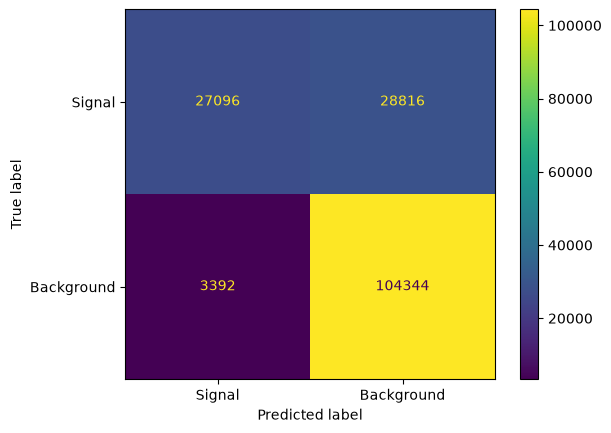

In [19]:
from sklearn.metrics import ConfusionMatrixDisplay
from sklearn.metrics import precision_score, accuracy_score

print("Evaluation metrics: ")
print(f"Accuracy: {accuracy_score(y,y_pred):.4f}")
print(f"Precision: {precision_score(y,y_pred):.4f}")
print(f"AMS: {ams(y_pred,y,weights):.4f}")

conf = ConfusionMatrixDisplay.from_predictions(
    y, y_pred,
    labels=[1, 0],
    display_labels=["Signal", "Background"],
    values_format="d",
    )

fig = conf.figure_
fig.savefig("figures/confusionMatrix.pdf")